<a href="https://colab.research.google.com/github/hersil7/cdd_ucsc/blob/main/S4_Entrega3_SILVA_HERNAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 3 · Minería de datos, validación y volumen
**Estudiante:** Hernán Silva · **Conjunto:** ENE 2025, panel de 4 visitas (`mi_conjunto_explorado.csv`)

**Pregunta de trabajo.** ¿Existen personas ocupadas cuya combinación de edad, horas habituales y nivel educativo se aleje de forma marcada del resto? Y si existen, ¿son error de registro o fenómeno real?

**Técnica principal:** detección de anomalías por distancia multivariada, con una verificación de sensibilidad sin la variable de nivel.

**Unidad de análisis:** persona ocupada (promedio de sus visitas ocupadas).

> **Limitación de datos (disclaimer).** La variable `meses_ocup_actual` presenta un error de conversión originado en la semana 2: 124 casos con 88 y 122 con 99 fueron tratados como faltantes sin ser códigos de no respuesta en esa variable, y 77 decimales (por ejemplo 1,5) se convirtieron en nulos por la coma decimal. En total 436 casos sin dato, de los cuales 323 son valores válidos. Por esta razón **la variable se excluye de este análisis**. Ninguna conclusión de esta entrega depende de ella. La corrección queda pendiente y se aplicará antes de reportar estadísticas de duración de la ocupación.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
import json, time, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
RUTA = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 3/'
pd.set_option('display.width', 120)

Se importan las librerías y se fija la semilla (42) para que los resultados sean reproducibles. `RUTA` queda vacía porque el archivo está en la misma carpeta del cuaderno.

In [ ]:
df = pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', low_memory=False)

# Se eliminan las variables derivadas de la división por edad (error de la semana 3)
df = df.drop(columns=['edad_edad', 'meses_ocup_actual_edad'], errors='ignore')

print('Forma del conjunto:', df.shape)
print('Columnas usadas en este análisis: edad, habituales, nivel_grupo, activ, idrph')

Forma del conjunto: (118760, 26)
Columnas usadas en este análisis: edad, habituales, nivel_grupo, activ, idrph


El conjunto tiene 118.760 registros y 26 columnas, después de eliminar `edad_edad` y `meses_ocup_actual_edad`, que venían de una división por edad que no aporta información. `meses_ocup_actual` no se usa en ningún paso (ver disclaimer). Las variables de trabajo son `edad`, `habituales`, `nivel_grupo` y `activ`.

In [ ]:
oc = df[pd.to_numeric(df['activ'], errors='coerce') == 1].copy()
oc['edad'] = pd.to_numeric(oc['edad'], errors='coerce')
oc['habituales'] = pd.to_numeric(oc['habituales'], errors='coerce')

# nivel como rango (ordinal): preserva el orden sin suponer distancias iguales entre niveles
oc['nivel_r'] = oc['nivel_grupo'].map({'Básica o menos': 1, 'Media': 2, 'Superior': 3}).rank(pct=True)

per = (oc.groupby('idrph')
         .agg(edad=('edad', 'mean'), habituales=('habituales', 'mean'),
              nivel_r=('nivel_r', 'mean'), n_visitas=('edad', 'size'))
         .dropna(subset=['edad', 'habituales', 'nivel_r']))

print('Registros ocupados:', len(oc), '| personas ocupadas:', len(per))
print('Visitas ocupadas por persona:', per['n_visitas'].value_counts().sort_index().to_dict())

Registros ocupados: 50106 | personas ocupadas: 15363
Visitas ocupadas por persona: {1: 1969, 2: 1638, 3: 2170, 4: 9586}


De los 50.106 registros ocupados se obtienen 15.363 personas: la unidad de análisis es la persona, con el promedio de sus visitas ocupadas. Esto evita que una misma persona aparezca varias veces como si fuera un caso distinto. El 62 % tiene las cuatro visitas ocupadas (9.586 personas) y el resto entre una y tres. Por eso se guarda `n_visitas` como descriptor. Las 7 personas que se descartan no tienen dato completo en alguna de las tres variables.

In [ ]:
def distancia(datos):
    """Distancia de cada persona al centro, con variables estandarizadas."""
    X = StandardScaler().fit_transform(datos)
    return np.linalg.norm(X - X.mean(axis=0), axis=1)

per['dist'] = distancia(per[['edad', 'habituales', 'nivel_r']])           # principal
per['dist_sin_nivel'] = distancia(per[['edad', 'habituales']])            # sensibilidad

print(per[['dist', 'dist_sin_nivel']].describe().round(3))

            dist  dist_sin_nivel
count  15363.000       15363.000
mean       1.621           1.254
std        0.611           0.653
min        0.396           0.015
25%        1.254           0.744
50%        1.568           1.138
75%        1.952           1.632
max        9.744           9.674


La distancia al centro tiene mediana 1,57 y una cola larga: el máximo (9,74) está muy por encima del tercer cuartil (1,95). La cola justifica un umbral alto. La variable `nivel_r` solo toma tres valores distintos (rangos de cada grupo), así que su peso en la distancia es más grueso que el de las otras dos; esto se declara como limitación.

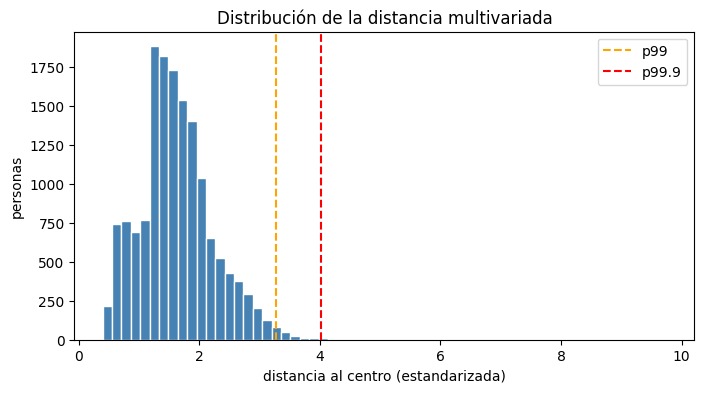

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per['dist'], bins=60, color='steelblue', edgecolor='white')
for q, c in [(0.99, 'orange'), (0.999, 'red')]:
    ax.axvline(per['dist'].quantile(q), color=c, ls='--', label=f'p{q*100:g}')
ax.set_xlabel('distancia al centro (estandarizada)')
ax.set_ylabel('personas')
ax.set_title('Distribución de la distancia multivariada')
ax.legend()
plt.show()

El histograma muestra un cuerpo concentrado y una cola derecha. Las líneas de p99 (naranja) y p99,9 (rojo) separan los casos que se apartan de forma marcada del resto. El umbral se fija a partir de esta forma, no por costumbre.

In [ ]:
UMBRAL = per['dist'].quantile(0.999)
marcados = per[per['dist'] > UMBRAL].sort_values('dist', ascending=False)
print(f'Umbral p99,9 = {UMBRAL:.3f} | personas marcadas = {len(marcados)} de {len(per)}')
marcados.round(2)

Umbral p99,9 = 4.021 | personas marcadas = 16 de 15363


,edad,habituales,nivel_r,n_visitas,dist,dist_sin_nivel
idrph,,,,,,
708661631137,32.00,168.00,0.80,1,9.74,9.67
785417997718,59.50,103.25,0.08,4,5.18,4.95
305039930939,56.00,105.00,0.80,1,5.18,5.04
295657698756,66.00,98.00,0.38,1,4.70,4.68
81205126043,60.25,94.50,0.80,4,4.49,4.34
499512264480,81.00,84.00,0.08,1,4.44,4.18
918065190524,55.75,96.50,0.38,4,4.44,4.42
772237990093,65.00,87.50,0.08,4,4.21,3.93
699757509293,56.50,92.75,0.38,4,4.18,4.16


Umbral declarado: p99,9 = 4,021. Se elige porque la pauta pide revisar entre 10 y 20 casos, y con este umbral se marcan 16 personas (0,10 % de 15.363). Con p99 se marcarían 153 y con p97 más de 400, lo que no permite revisar uno a uno. Los casos superiores son: una persona con 168 horas habituales y solo una visita ocupada, y varias con 90 a 105 horas habituales. Los tres primeros se caracterizan en la celda 8.

In [ ]:
UMBRAL_S = per['dist_sin_nivel'].quantile(0.999)
marcados_s = per[per['dist_sin_nivel'] > UMBRAL_S]
comunes = set(marcados.index) & set(marcados_s.index)

print('Marcados sin nivel:', len(marcados_s), '| en común con el análisis principal:', len(comunes))
print('Solo en el principal:', sorted(set(marcados.index) - set(marcados_s.index)))
print('Solo en sensibilidad:', sorted(set(marcados_s.index) - set(marcados.index)))

Marcados sin nivel: 16 | en común con el análisis principal: 14
Solo en el principal: [1577698329, 624610661338]
Solo en sensibilidad: [524705177112, 673875963396]


La sensibilidad sin la variable de nivel coincide en 14 de 16 casos. Las dos personas que solo aparecen con nivel (1577698329 y 624610661338) tienen nivel básico o menos y edades altas (68 y 94 años), así que el nivel empuja su distancia hacia afuera al combinarse con la edad. Las dos que solo aparecen sin nivel (524705177112 y 673875963396) tienen 87 a 89 horas habituales y nivel medio o superior. El resultado es estable: la dimensión educativa cambia solo dos casos, y se reporta en la sección de limitaciones.

In [ ]:
cols_v = ['idrph', 'mes_central', 'activ', 'edad', 'habituales', 'nivel_grupo']
for p in marcados.index[:3]:
    print(f'--- persona {p} (distancia {marcados.loc[p, "dist"]:.2f}) ---')
    print(df.loc[df['idrph'] == p, cols_v].to_string(index=False))
    print()

--- persona 708661631137 (distancia 9.74) ---
       idrph  mes_central  activ  edad  habituales nivel_grupo
708661631137            2    2.0    31         NaN    Superior
708661631137            5    3.0    31         NaN    Superior
708661631137            8    3.0    32         NaN    Superior
708661631137           11    1.0    32       168.0    Superior

--- persona 785417997718 (distancia 5.18) ---
       idrph  mes_central  activ  edad  habituales    nivel_grupo
785417997718            2    1.0    59       105.0 Básica o menos
785417997718            5    1.0    59        98.0 Básica o menos
785417997718            8    1.0    60       112.0 Básica o menos
785417997718           11    1.0    60        98.0 Básica o menos

--- persona 305039930939 (distancia 5.18) ---
       idrph  mes_central  activ  edad  habituales nivel_grupo
305039930939            2    3.0    56         NaN    Superior
305039930939            5    3.0    56         NaN    Superior
305039930939            8 

Caracterización de los tres casos superiores con sus visitas originales:

1. **708661631137** (distancia 9,74). Solo una de sus cuatro visitas es ocupada (mes central 11), y en esa visita declara 168 horas habituales, es decir, todas las horas de la semana. En las otras tres visitas aparece como desocupada o fuera de la fuerza de trabajo, con horas vacías. Un valor de 168 horas habituales en una única visita es **muy probablemente un error de registro**. Se declara y se excluye de las estadísticas de horas.

2. **785417997718** (distancia 5,18). Es ocupada en las cuatro visitas, con 98 a 112 horas habituales en todas ellas. Como el patrón se repite, no es un error puntual de una visita. Puede corresponder a varios empleos sumados o a una declaración sistemática, pero el archivo no permite distinguirlos. **Queda como caso no concluyente**: extremo y persistente, sin evidencia suficiente para clasificarlo como error o como fenómeno real.

3. **305039930939** (distancia 5,18). Solo es ocupada en una visita (mes central 8), con 105 horas habituales. En las otras tres aparece como fuera de la fuerza de trabajo, sin horas. Es el mismo patrón del caso 1, aunque con menos horas: **probablemente error de registro o una actividad mal asignada en esa visita**.

Resumen: dos de los tres casos superiores tienen una sola visita ocupada con horas extremas, lo que apunta a error de registro. Uno es persistente y queda como no concluyente.

In [ ]:
referencia = set(marcados.index)
res = []
for r in range(30):
    rng = np.random.default_rng(r)
    mitad = rng.random(len(per)) < 0.5
    for sub in [per[mitad], per[~mitad]]:
        d = pd.Series(distancia(sub[['edad', 'habituales', 'nivel_r']]), index=sub.index)
        t = d.quantile(0.999)
        m_mitad = set(d[d > t].index)
        ref_en_mitad = referencia & set(sub.index)
        rec = m_mitad & ref_en_mitad
        res.append({'marcados_en_mitad': len(m_mitad),
                    'referencia_en_mitad': len(ref_en_mitad),
                    'proporcion_recuperada': len(rec) / len(ref_en_mitad) if ref_en_mitad else np.nan})

R = pd.DataFrame(res)
print('Submuestreo repetido: 30 particiones por persona, 2 mitades cada una')
print(R.agg(['mean', 'std']).round(3).to_string())

Submuestreo repetido: 30 particiones por persona, 2 mitades cada una
      marcados_en_mitad  referencia_en_mitad  proporcion_recuperada
mean                8.0                8.000                  0.934
std                 0.0                1.747                  0.096


Validación por submuestreo repetido: se repiten 30 particiones aleatorias de las personas en dos mitades, y en cada mitad se recalcula todo (estandarización, centro y umbral p99,9). En promedio, cada mitad marca 8 personas y recupera el 93,4 % de los casos de referencia que contiene, con desviación de 9,6 puntos. El ranking de los casos extremos es estable en mitades independientes. El conteo exacto es inestable porque cada mitad tiene solo unas 8 personas marcadas, así que el hallazgo se sostiene en su orden de magnitud, no en el número exacto de casos.

In [ ]:
def estrategia_a():
    d = pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', low_memory=False)
    d = d[pd.to_numeric(d['activ'], errors='coerce') == 1]
    return d.groupby('idrph').agg(edad=('edad', 'mean'), habituales=('habituales', 'mean'))

def estrategia_b():
    d = pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', low_memory=False,
                    usecols=['idrph', 'activ', 'edad', 'habituales'])
    d = d[pd.to_numeric(d['activ'], errors='coerce') == 1]
    return d.groupby('idrph').agg(edad=('edad', 'mean'), habituales=('habituales', 'mean'))

def estrategia_c():
    acum = []
    for trozo in pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', low_memory=False,
                             usecols=['idrph', 'activ', 'edad', 'habituales'], chunksize=20000):
        trozo = trozo[pd.to_numeric(trozo['activ'], errors='coerce') == 1]
        acum.append(trozo.groupby('idrph').agg(s_e=('edad', 'sum'), n_e=('edad', 'count'),
                                              s_h=('habituales', 'sum'), n_h=('habituales', 'count')))
    t = pd.concat(acum).groupby(level=0).sum()
    return pd.DataFrame({'edad': t['s_e'] / t['n_e'], 'habituales': t['s_h'] / t['n_h']})

def medir(fn):
    tracemalloc.start()
    t0 = time.perf_counter()
    out = fn()
    tiempo = time.perf_counter() - t0
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return out, tiempo, pico / 1e6

A, tA, mA = medir(estrategia_a)
B, tB, mB = medir(estrategia_b)
C, tC, mC = medir(estrategia_c)

costo = pd.DataFrame({'estrategia': ['A: leer todo', 'B: columnas necesarias', 'C: por bloques'],
                      'tiempo_s': [round(tA, 3), round(tB, 3), round(tC, 3)],
                      'pick_memoria_MB': [round(mA, 1), round(mB, 1), round(mC, 1)]})
costo

,estrategia,tiempo_s,pick_memoria_MB
0,A: leer todo,0.891,84.0
1,B: columnas necesarias,0.364,13.4
2,C: por bloques,0.405,6.1


Comparación de costo computacional con tiempo y memoria medidos aquí: la estrategia A (leer todo el archivo) tarda 0,891 s y usa 84,0 MB; la B (solo las columnas necesarias) tarda 0,364 s y usa 13,4 MB; la C (por bloques) tarda 0,405 s y usa 6,1 MB. Para este tamaño, leer solo lo necesario reduce la memoria unas seis veces. La diferencia de tiempo es pequeña, así que el criterio práctico es la memoria. La estrategia C solo gana si el archivo no cabe en memoria. Cambiaría de herramienta (por ejemplo a polars o duckdb) si el archivo superara la memoria disponible o si las consultas se repitieran muchas veces.

In [ ]:
for nombre, x in [('B', B), ('C', C)]:
    ok = np.allclose(A.loc[x.index, ['edad', 'habituales']].values,
                     x[['edad', 'habituales']].values, equal_nan=True)
    print(f'Estrategia {nombre} da el mismo resultado que A:', ok)
print('Personas en A:', len(A), '| en B:', len(B), '| en C:', len(C))

Estrategia B da el mismo resultado que A: True
Estrategia C da el mismo resultado que A: True
Personas en A: 15370 | en B: 15370 | en C: 15370


Verificación: las estrategias B y C dan el mismo resultado que A para edad y horas habituales. La diferencia de conteo entre A (15.370 personas) y la unidad de análisis (15.363) corresponde a las 7 personas sin dato completo, que se excluyen solo en el análisis y no en la verificación de volumen.

## Respuesta: ¿el hallazgo principal sostiene una decisión o solo sugiere una hipótesis?

Las dos cosas, en niveles distintos.

**Sostiene una decisión de calidad de datos.** Los registros con horas habituales extremas y una sola visita ocupada son, con la evidencia del propio conjunto, probablemente errores de registro. Esa evidencia es sólida: se repite en el caso superior y en el tercero, y la validación por mitades mantiene el ranking de los extremos. La decisión que sí sostiene es declarar y excluir esos registros de las estadísticas de horas, y dejar señalado el caso persistente.

**Solo sugiere una hipótesis sustantiva.** Que existan personas que trabajan de forma persistente más de 90 horas habituales (como el caso 785417997718) puede ser un fenómeno real de empleo intensivo, o una declaración sistemática. Con 16 casos y sin los cuestionarios originales, no hay evidencia para afirmarlo. La hipótesis a probar sería: los casos persistentes de horas extremas se concentran en empleos informales o con varios trabajos sumados. Su refutación sería que, al revisar el cuestionario original, esas horas correspondan a un solo empleo declarado con esa duración.

**Cifras para la sección de limitaciones:** 15.363 personas ocupadas; umbral p99,9 = 4,021; 16 casos marcados; 14 de 16 coinciden sin la variable de nivel; reproducción por mitades de 93,4 % (desviación 9,6 puntos); exclusión de `meses_ocup_actual` por error de conversión en la semana 2 (436 casos sin dato, 323 válidos); una variable de nivel con solo tres valores.

---
**Enlace a mi repositorio:** [https://github.com/hersil7/cdd_ucsc](https://github.com/hersil7/cdd_ucsc)